# 01 - Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Goal:** understand the data before modelling: its quality, the class balance, how each feature relates to heart disease, and what that implies for the preprocessing pipeline.

**Dataset choice.** The assignment names the UCI Heart Disease dataset. I use the **Cleveland subset** (`processed.cleveland.data`, 303 patients, 14 attributes) from the official UCI repository because:
- It is the only one of the four UCI sites with near-complete data. The Hungarian, Swiss and VA files are missing most `ca`/`thal`/`slope` values, and merging them would mean imputing over half of some columns.
- It is the subset used in almost all published work, so results are comparable.
- It is downloaded from the primary source by a script and checksummed, rather than taken from a re-uploaded Kaggle copy. The popular Kaggle `heart.csv` re-encodes several columns, inverts the target and turns the missing values into fake categories (`ca = 4`, `thal = 0`).

Run `python scripts/download_data.py` first.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display
%matplotlib inline

from src import eda
from src.config import RAW_MANIFEST, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES
from src.data_processing import load_raw, clean, missing_report, save_clean

pd.set_option("display.width", 120)
FIG_DIR = ROOT / "reports" / "figures"
print(json.dumps(json.loads(RAW_MANIFEST.read_text()), indent=2))

{
  "dataset": "UCI Heart Disease - Cleveland subset",
  "source": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
  "file": "processed.cleveland.data",
  "rows": 303,
  "columns": [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
  ],
  "sha256": "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8",
  "downloaded_at_utc": "2026-10-12T10:07:08+00:00"
}


## 1. Raw data
The raw file has no header. Missing values are written as `?`.

In [2]:
raw = load_raw()
print("Raw shape:", raw.shape)
display(raw.head())
print("\nDiagnosis `num` (0 = none, 1-4 = severity):")
print(raw["num"].value_counts().sort_index().to_string())

Raw shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Diagnosis `num` (0 = none, 1-4 = severity):
num
0    164
1     55
2     36
3     35
4     13


## 2. Cleaning
Rules (implemented in `src/data_processing.py`):
1. Assign the 14 documented column names.
2. `?` becomes NaN. Values are **not** imputed here; imputation lives inside the sklearn pipeline so it is fitted on training folds only.
3. Categorical codes outside the documented set become NaN.
4. `num` is collapsed to a binary `target` (0 = no disease, 1-4 = disease) and then dropped.
5. Exact duplicate rows are removed.

Clean shape: (303, 14)


,missing,percent
ca,4,1.32
thal,2,0.66


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
dtype,Int64,float64,float64,float64,float64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,int64


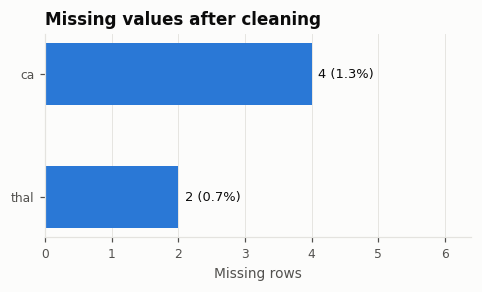

In [3]:
df = clean(raw)
print("Clean shape:", df.shape)
display(missing_report(df))
display(df.dtypes.to_frame("dtype").T)
eda.plot_missing_values(df, FIG_DIR);

Only `ca` and `thal` have gaps, in about 2% of patients. Dropping those rows would also be defensible. I keep them and impute with the most frequent value inside the model pipeline, which loses no patients and lets the API accept a request with an unknown `ca` or `thal`.

In [4]:
out = save_clean(df)
print("Saved", out.relative_to(ROOT))

Saved data\processed\heart_clean.csv


## 3. Target balance

target
0    0.541
1    0.459


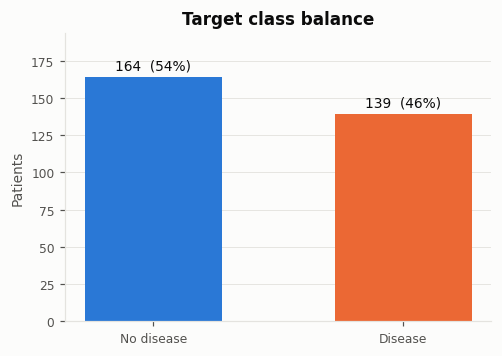

In [5]:
eda.plot_class_balance(df, FIG_DIR);
print(df[TARGET].value_counts(normalize=True).round(3).to_string())

The classes are roughly balanced (about 54% / 46%), so no resampling is needed. Accuracy is still not enough on its own. In a screening setting a missed disease case (false negative) is costlier than a false alarm, so **recall** and **ROC-AUC** will be the main selection metrics, with stratified CV to preserve the ratio in every fold.

## 4. Numeric features

,mean,std,min,median,max,mean_no_disease,mean_disease
feature,,,,,,,
age,54.44,9.04,29.0,56.0,77.0,52.59,56.63
trestbps,131.69,17.60,94.0,130.0,200.0,129.25,134.57
chol,246.69,51.78,126.0,241.0,564.0,242.64,251.47
thalach,149.61,22.88,71.0,153.0,202.0,158.38,139.26
oldpeak,1.04,1.16,0.0,0.8,6.2,0.59,1.57


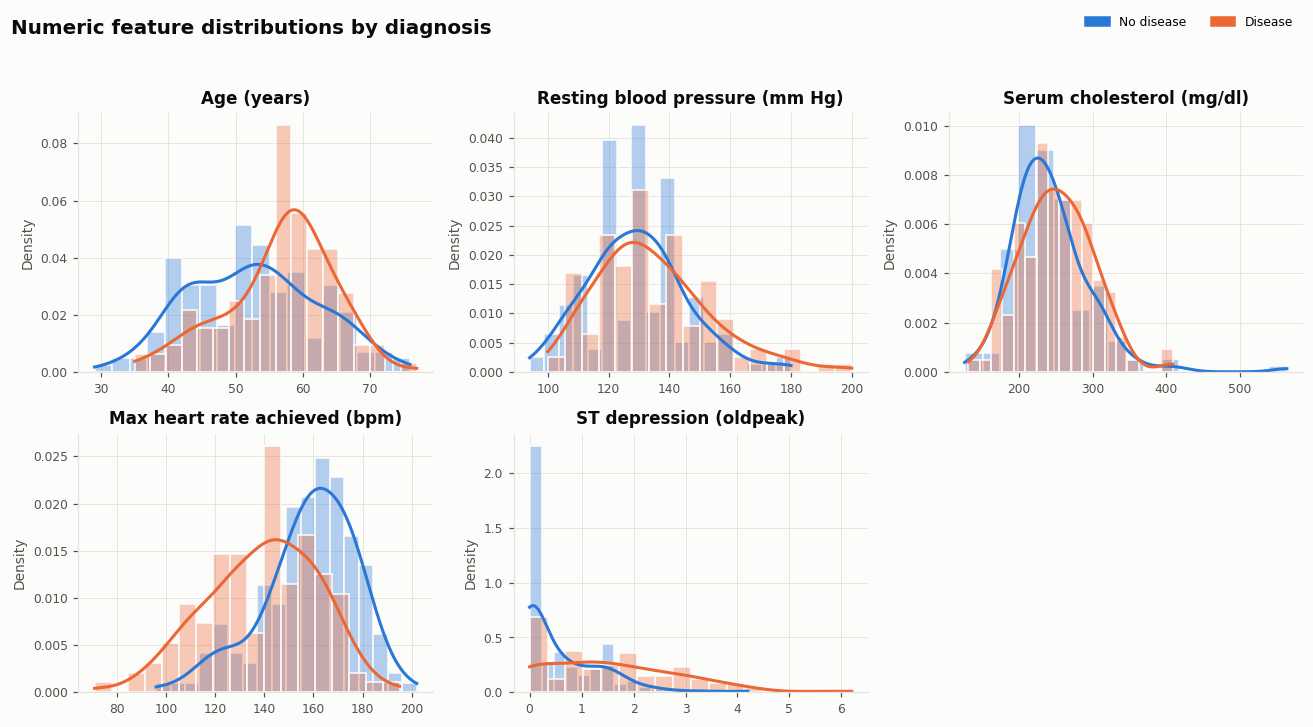

In [6]:
display(eda.summary_table(df))
eda.plot_numeric_distributions(df, FIG_DIR);

- **thalach (max heart rate)** separates the classes best: patients with disease reach a lower peak heart rate.
- **oldpeak (ST depression)** is strongly right-skewed with a spike at 0, and the disease class has the long tail.
- **age** is shifted older for the disease class but overlaps heavily.
- **chol** and **trestbps** barely differ between classes, so they are weak predictors on their own.
- The features use very different scales (oldpeak 0-6 vs chol 126-564), so **scaling is required** for linear models and SVMs.

## 5. Outliers

,lower_fence,upper_fence,n_outliers,outlier_values
feature,,,,
age,28.50,80.50,0,[]
trestbps,90.00,170.00,9,"[172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180..."
chol,115.00,371.00,5,"[394.0, 407.0, 409.0, 417.0, 564.0]"
thalach,84.75,214.75,1,[71.0]
oldpeak,-2.40,4.00,5,"[4.2, 4.2, 4.4, 5.6, 6.2]"


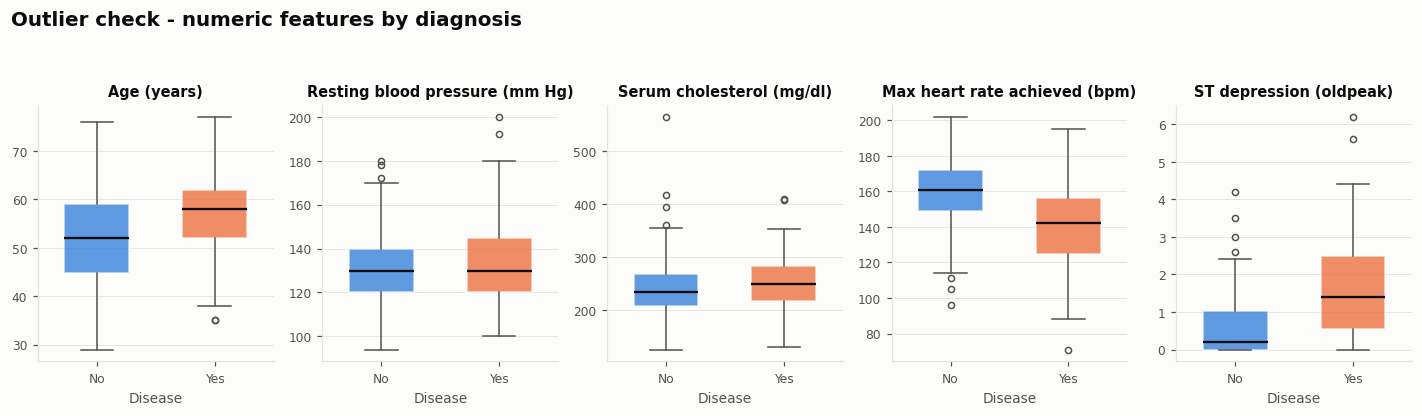

In [7]:
display(eda.outlier_table(df)[['lower_fence','upper_fence','n_outliers','outlier_values']])
eda.plot_numeric_boxplots(df, FIG_DIR);

The Tukey-fence outliers (e.g. cholesterol 564, resting BP 200, oldpeak 6.2) are clinically plausible extreme values, not data-entry errors, so they are **kept**. Tree models are insensitive to them. For linear models, `StandardScaler` is adequate at this sample size, and `RobustScaler` is an option to compare during tuning.

## 6. Categorical features

,feature,level,n,disease_rate_%
0,sex,Female,97,25.8
1,sex,Male,206,55.3
2,cp,Typical angina,23,30.4
3,cp,Atypical angina,50,18.0
4,cp,Non-anginal pain,86,20.9
5,cp,Asymptomatic,144,72.9
6,fbs,<= 120 mg/dl,258,45.3
7,fbs,> 120 mg/dl,45,48.9
8,restecg,Normal,151,37.1
9,restecg,ST-T abnormality,4,75.0


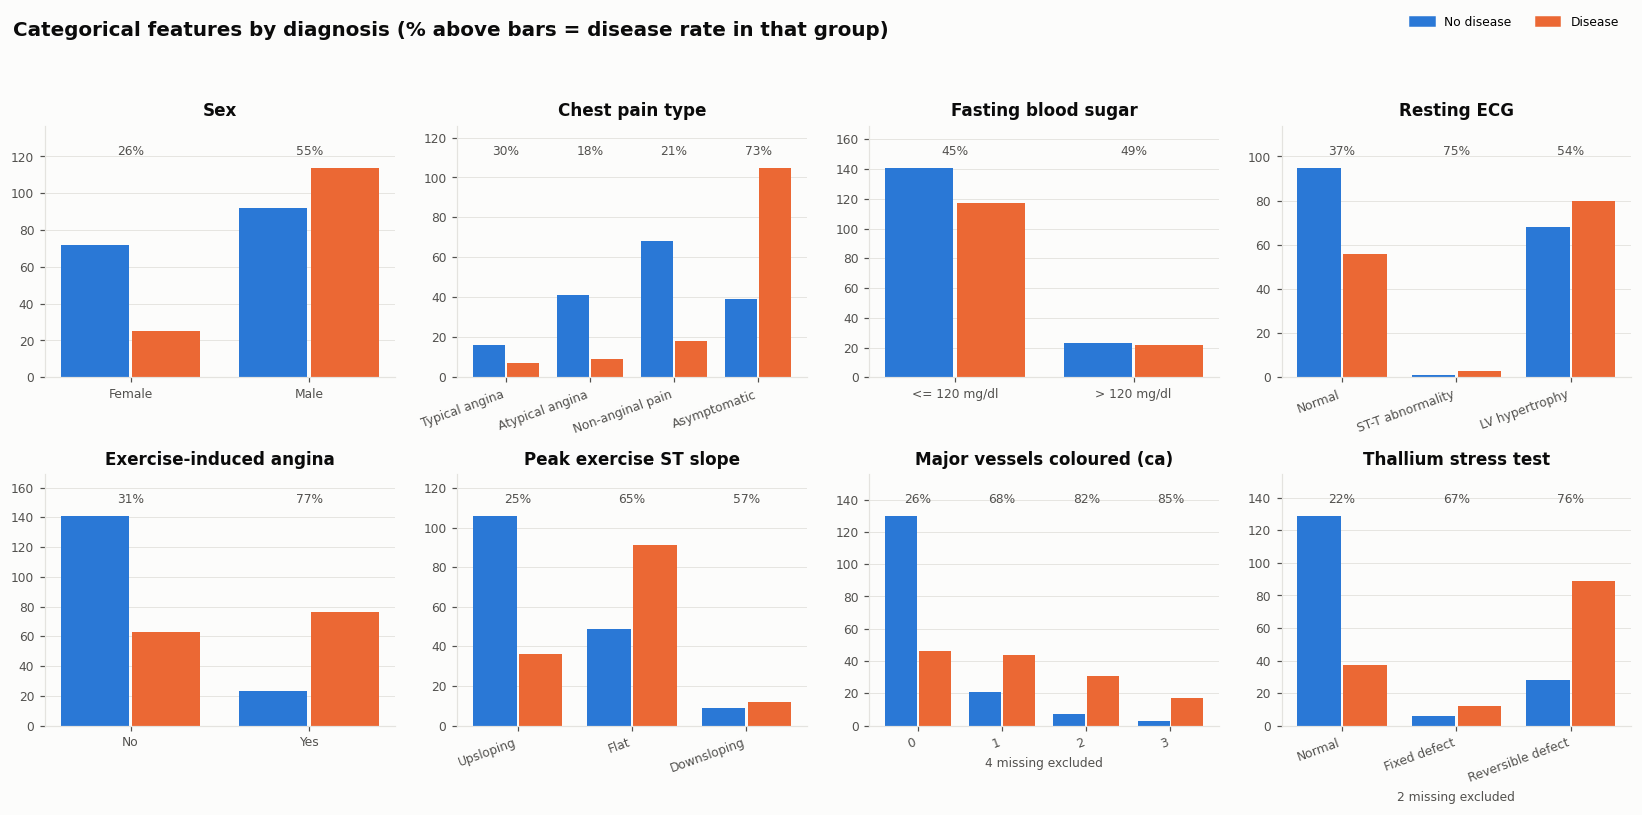

In [8]:
eda.plot_categorical_counts(df, FIG_DIR);
display(eda.disease_rate_table(df))

- **cp = asymptomatic** has the highest disease rate (about 73%). Patients with "typical" chest pain are mostly disease-free. This is counter-intuitive but well documented for this dataset.
- **ca** (vessels coloured) has a near-monotonic dose-response: about 26% disease at 0 vessels and over 80% at 2-3.
- **thal = reversible defect**, **exang = yes** and **slope = flat** each point strongly to disease.
- Males have about twice the disease rate of females (55% vs 25%).
- **fbs** carries almost no signal (45% vs 49%).
- **restecg = ST-T abnormality** has only 4 patients. That level is too rare to learn from, so `OneHotEncoder(handle_unknown="ignore")` is needed in case a CV fold never sees it.

These codes are **nominal**, not ordinal (e.g. `thal` = 3/6/7), so they will be **one-hot encoded**, not scaled as numbers.

## 7. Correlations

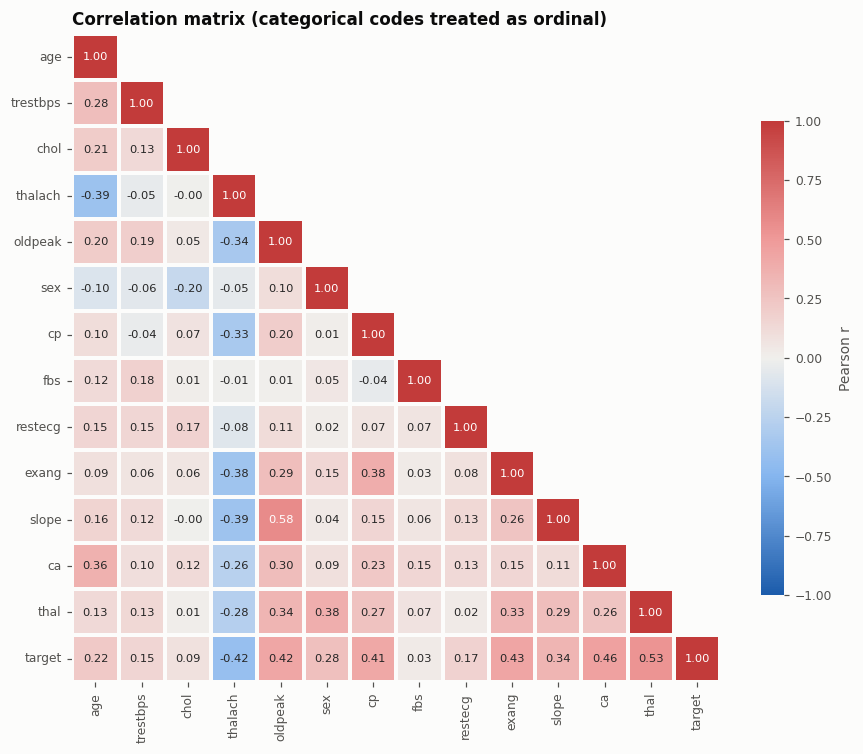

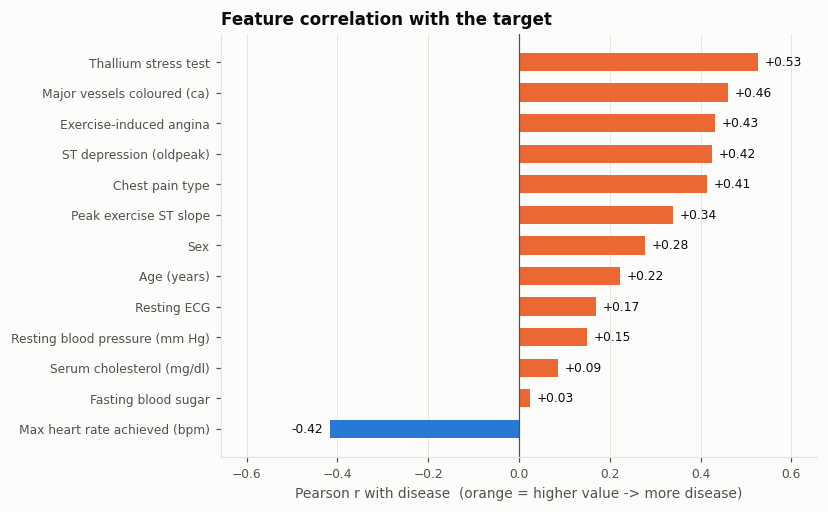

In [9]:
eda.plot_correlation_heatmap(df, FIG_DIR);
eda.plot_target_correlation(df, FIG_DIR);

- The strongest single associations with the target are `thal`, `ca`, `exang`, `oldpeak`, `cp` and `thalach` (negative), all with |r| of about 0.4-0.5. No single feature dominates, so a multivariate model should do clearly better than any one feature.
- The largest correlation between two features is `oldpeak`-`slope` (about 0.58), well below a level that causes collinearity problems. All 13 features are kept.
- `fbs` and `chol` are close to zero, so regularisation (L1/L2 in logistic regression) or tree-based importance can down-weight them. I don't hand-drop them, to avoid choices driven by test-set peeking.

*(Pearson on categorical codes is only an approximate screen. The one-hot model treats them properly.)*

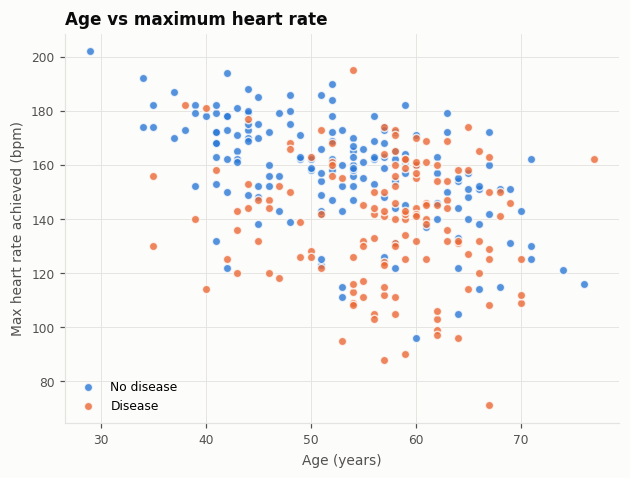

In [10]:
eda.plot_age_vs_thalach(df, FIG_DIR);

Max heart rate falls with age, and at any given age patients with disease tend to sit lower. This shows why the two features together carry more information than either one alone.

## 8. Summary and implications for modelling

| Finding | Decision for the pipeline |
|---|---|
| 303 patients, 6 with missing `ca`/`thal` (about 2%) | Keep all rows. `SimpleImputer` inside the pipeline (median for numeric, most-frequent for categorical) |
| Classes about 54/46 | No resampling. Stratified 5-fold CV. Select on recall + ROC-AUC |
| Numeric features on very different scales | `StandardScaler` on the 5 numeric features |
| 8 nominal categorical codes, some rare levels | `OneHotEncoder(handle_unknown="ignore")` |
| Outliers are plausible clinical values | Keep them. Optionally compare with `RobustScaler` |
| No strong multicollinearity. Several moderate predictors | Keep all 13 features. Compare a linear model (interpretable) with tree ensembles (interactions) |

Figures are saved to `reports/figures/` for the report.

In [11]:
sorted(p.name for p in FIG_DIR.glob("*.png"))

['00_missing_values.png',
 '01_class_balance.png',
 '02_numeric_distributions.png',
 '03_numeric_boxplots.png',
 '04_categorical_counts.png',
 '05_correlation_heatmap.png',
 '06_target_correlation.png',
 '07_age_vs_thalach.png']